# Observability of cluster concentrations with weak lensing

**Question.** How close to the cluster centre must $\Delta\Sigma$ be measured to constrain the NFW concentration?
*"If you want to measure a concentration $c$, you need data down to radius $Y$."*

**Idea.** The NFW density slope runs from $-1$ (inside) to $-3$ (outside) and is $-2$ at $r_s = r_{200m}/c$:
$c$ only sets **where the knee is**. Apart from amplitude, $\rho$, $\Sigma$ and $\Delta\Sigma$ are universal functions
of $x = R/r_s$, so concentration is measurable only if the data reach far enough in to see the bend.

Everything here is **noise-free** and uses the pipeline's own model (`destacking.model._nfw_components` → xlensing NFW).
Rebuilt 2026-09-28 (the original version plotted the $\Delta\Sigma$ and $\gamma$ families with $r_s$ marked; both views are kept, §2 and §4).

**Headline results** (log $M_{200m}$ = 14–15, $z$ = 0.3, data out to 4 Mpc):
1. The knee in $\Delta\Sigma$ is **not** at $r_s$: $\Delta\Sigma$ is flat in the centre (slope 0) and bends to slope $-1$ at $R \approx 2.8\,r_s$.
2. After refitting the mass, a halo keeps **half of its concentration sensitivity** if the data reach $r_{\min} \approx (0.7$–$1.4)\,r_s$ — i.e. **you need data down to about $r_s = r_{200m}/c$**.
3. The 0.16–0.25 Mpc annulus carries 6–24 % of the sensitivity, **most for low-mass, high-$c$ haloes**. With $\gamma_{cm} > 0$ those are the high-$\Delta m$ clusters, which is why an inner-bin systematic would leak into $\gamma_{cm}$ (§6).
4. The simulator reproduces the model to ≤ 0.3 % in every bin for $c$ up to 12, noise-free — so any inner-bin problem is noise-related, not a model mismatch (§7).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors, cm
from scipy.optimize import minimize_scalar
from astropy import constants as const, units as u
from astropy.cosmology import Planck18

import xlensing.model as xm
from destacking.model import _nfw_components, diemer19_c200m

plt.rcParams.update({"font.size": 10.5, "xtick.direction": "in", "ytick.direction": "in"})

# ---- parameters (edit freely) ----
Z = 0.3                     # lens redshift
LOGM = 14.5                 # reference mass, log10 M200m [Msun]
R_MAX = 4.0                 # outermost radius of the data [Mpc]
C_VALUES = [2.0, 3.0, 4.0, 6.0, 8.0, 12.0]
DC = 0.20                   # fractional concentration change used to measure sensitivity
INNER_CUTS = [0.16, 0.25, 0.5]   # inner radii used in this project [Mpc]
R = np.logspace(-2.5, np.log10(R_MAX), 400)
RMINS = np.logspace(-2.3, np.log10(2.0), 40)
TRUTH_PATH = "~/destacking_data/output/step0/LSSTrb2/sim/simulation_g00_gamma+0.2/truth_catalog.npz"

Lookup tables loaded!


In [2]:
def r200(logm, z=Z):
    return xm.r_vir_m(np.array([z]), np.array([10**logm]))[0]

def rs(logm, c, z=Z):
    return r200(logm, z) / c

def dsig(logm, c, radii=R, z=Z):
    # point-evaluated, centred NFW Delta Sigma [Msun/pc^2]
    cen, _ = _nfw_components(np.array([z]), np.array([10**logm]), np.array([c]), radii, bin_nodes=0)
    return cen[0]

def sigma(logm, c, radii=R, z=Z):
    # centred NFW Sigma [Msun/pc^2], same normalisation as xlensing
    M = np.array([10**logm]); C = np.array([c]); zz = np.array([z])
    r_s = xm.r_vir_m(zz, M)[0] / c
    fact = 2 * r_s * xm.NFW_delta_c(C)[0] * xm.cosmo.rhoM(zz)[0] / 1e12
    return fact * xm.SigX(radii / r_s)

def residual(logm, c, c2, rmin, z=Z):
    # max |ln DeltaSigma difference| on [rmin, R_MAX] between (logm, c) and the best-matching (logm', c2)
    m = R >= rmin
    ref = np.log(dsig(logm, c, z=z)[m])
    f = lambda lm: np.max(np.abs(np.log(dsig(lm, c2, z=z)[m]) - ref))
    return minimize_scalar(f, bounds=(logm - 0.6, logm + 0.6), method="bounded", options={"xatol": 1e-5}).fun

def sensitivity(logm, c, rmin, z=Z):
    # residual for a +/-DC change of c (worse of the two), mass refitted
    return max(residual(logm, c, c * (1 + DC), rmin, z), residual(logm, c, c * (1 - DC), rmin, z))

print(f"r200m(logM={LOGM}, z={Z}) = {r200(LOGM):.3f} Mpc;  Diemer+19 c200m = {np.ravel(diemer19_c200m(10**LOGM, Z))[0]:.2f}")

r200m(logM=14.5, z=0.3) = 1.913 Mpc;  Diemer+19 c200m = 5.21


## 1. Where is the knee? Universal slopes

Local logarithmic slopes of $\rho(r)$, $\Sigma(R)$ and $\Delta\Sigma(R)$ against $R/r_s$. These depend on nothing else.
Green dotted lines: the inner cuts used in this project, for $c=4$ at the reference mass.

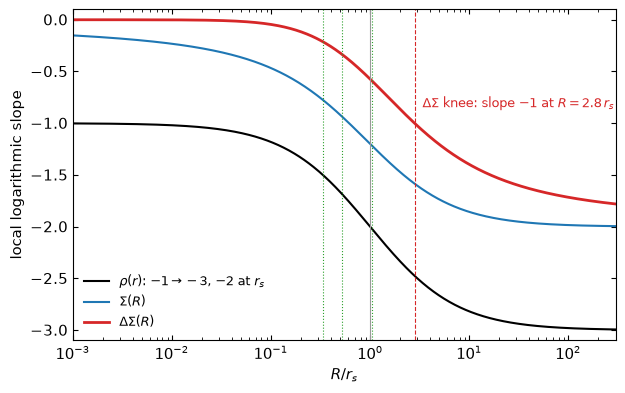

Sigma slope -1 at x = 0.61 ; DeltaSigma slope -1 at x = 2.81 ; DeltaSigma slope at x = 0.01, 0.1, 1, 10: [-0.0, -0.05, -0.57, -1.4]


In [3]:
x = np.logspace(-3, 2.5, 800); lnx = np.log(x)
slope_rho = -(1 + 3 * x) / (1 + x)
slope_sig = np.gradient(np.log(xm.SigX(x)), lnx)
slope_ds = np.gradient(np.log(xm.SigBar(x) - xm.SigX(x)), lnx)
x_at = lambda sl, s: np.exp(np.interp(s, sl[::-1], lnx[::-1]))
XK = x_at(slope_ds, -1.0)

fig, ax = plt.subplots(figsize=(7, 4.3))
ax.plot(x, slope_rho, "k", label=r"$\rho(r)$: $-1\to-3$, $-2$ at $r_s$")
ax.plot(x, slope_sig, "C0", label=r"$\Sigma(R)$")
ax.plot(x, slope_ds, "C3", lw=2, label=r"$\Delta\Sigma(R)$")
ax.axvline(1, color="0.6", lw=0.8); ax.axvline(XK, color="C3", lw=0.8, ls="--")
for r0 in INNER_CUTS:
    ax.axvline(r0 / rs(LOGM, 4.0), color="C2", lw=0.8, ls=":")
ax.text(XK * 1.2, -0.85, rf"$\Delta\Sigma$ knee: slope $-1$ at $R={XK:.1f}\,r_s$", color="C3", fontsize=9)
ax.set_xscale("log"); ax.set_xlim(1e-3, 3e2); ax.set_ylim(-3.1, 0.1)
ax.set_xlabel(r"$R/r_s$"); ax.set_ylabel("local logarithmic slope"); ax.legend(frameon=False, fontsize=9, loc="lower left")
ax.tick_params(top=True, right=True, which="both")
plt.show()
print("Sigma slope -1 at x =", round(x_at(slope_sig, -1), 2), "; DeltaSigma slope -1 at x =", round(XK, 2),
      "; DeltaSigma slope at x = 0.01, 0.1, 1, 10:", [round(float(np.interp(np.log(v), lnx, slope_ds)), 2) for v in (0.01, 0.1, 1, 10)])

## 2. The $\Delta\Sigma$ family at fixed mass

All profiles at fixed $M_{200m}$ cross near $R \sim 2$ Mpc (the mass pivot); concentration moves $r_s$ (dots) and the
inner amplitude. The cyan band is the Diemer & Joyce (2019) prediction ±10 %; grey lines are the inner cuts.

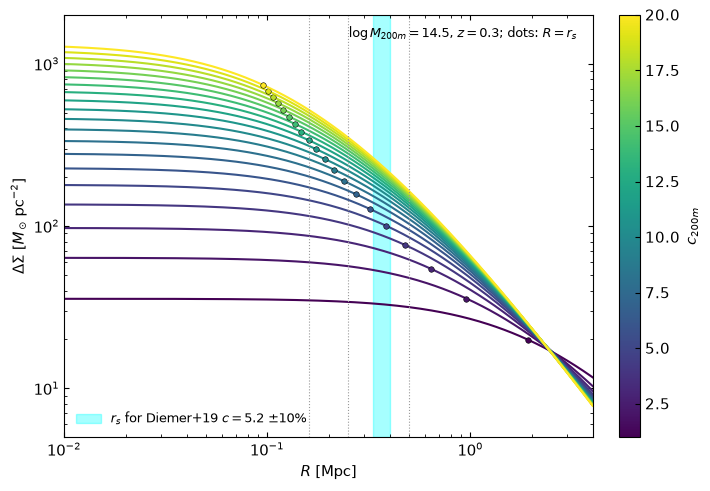

In [4]:
cmin, cmax = 1.0, 20.0
norm = colors.Normalize(vmin=cmin, vmax=cmax); cmap = plt.get_cmap("viridis")
cpred = np.ravel(diemer19_c200m(10**LOGM, Z))[0]
fig, ax = plt.subplots(figsize=(7, 4.8), layout="constrained")
ax.axvspan(0.9 * rs(LOGM, cpred), 1.1 * rs(LOGM, cpred), color="cyan", alpha=0.35, label=rf"$r_s$ for Diemer+19 $c={cpred:.1f}$ ±10%")
for c in np.linspace(cmin, cmax, 20):
    d = dsig(LOGM, c)
    ax.plot(R, d, color=cmap(norm(c)))
    ax.plot(rs(LOGM, c), np.interp(np.log(rs(LOGM, c)), np.log(R), d), "o", color=cmap(norm(c)), mec="k", mew=0.4, ms=4)
for r0 in INNER_CUTS:
    ax.axvline(r0, color="0.6", lw=0.8, ls=":")
fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label=r"$c_{200m}$")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(1e-2, R_MAX); ax.set_ylim(5, 2e3)
ax.set_xlabel(r"$R$ [Mpc]"); ax.set_ylabel(r"$\Delta\Sigma$ [$M_\odot\,{\rm pc}^{-2}$]")
ax.text(0.97, 0.97, rf"$\log M_{{200m}}={LOGM}$, $z={Z}$; dots: $R=r_s$", transform=ax.transAxes, ha="right", va="top", fontsize=9)
ax.legend(frameon=False, fontsize=9, loc="lower left"); ax.tick_params(top=True, right=True, which="both")
plt.show()

## 3. How much concentration sensitivity survives an inner cut?

For data on $[r_{\min}, R_{\max}]$, compare a halo with $c$ against one with $c(1\pm20\%)$, **refitting the mass** of the
second (this absorbs every amplitude change, so only the *shape* information is left). The maximum residual is the
noise-free sensitivity to concentration. Plotted against $r_{\min}/r_s$ the curves nearly collapse.

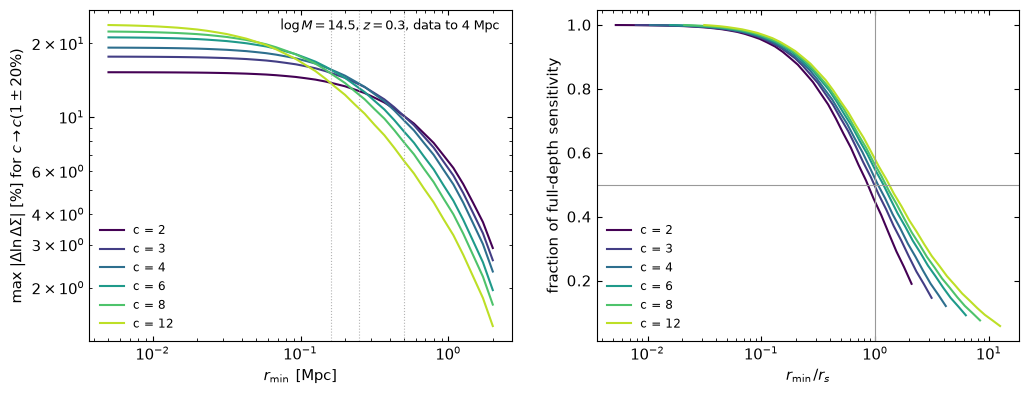

In [5]:
RES = {c: np.array([sensitivity(LOGM, c, r) for r in RMINS]) for c in C_VALUES}
cols = plt.cm.viridis(np.linspace(0, 0.9, len(C_VALUES)))
fig, axs = plt.subplots(1, 2, figsize=(12, 4.3))
for c, col in zip(C_VALUES, cols):
    axs[0].plot(RMINS, 100 * RES[c], color=col, label=f"c = {c:g}")
    axs[1].plot(RMINS / rs(LOGM, c), RES[c] / RES[c][0], color=col, label=f"c = {c:g}")
for r0 in INNER_CUTS:
    axs[0].axvline(r0, color="0.7", lw=0.8, ls=":")
axs[1].axvline(1, color="0.6", lw=0.8); axs[1].axhline(0.5, color="0.6", lw=0.8)
axs[0].set_xlabel(r"$r_{\min}$ [Mpc]"); axs[0].set_ylabel(r"max $|\Delta\ln\Delta\Sigma|$ [%] for $c\to c(1\pm20\%)$")
axs[0].set_yscale("log")
axs[1].set_xlabel(r"$r_{\min}/r_s$"); axs[1].set_ylabel("fraction of full-depth sensitivity")
for a in axs:
    a.set_xscale("log"); a.legend(frameon=False, fontsize=8.5, loc="lower left"); a.tick_params(top=True, right=True, which="both")
axs[0].text(0.97, 0.97, rf"$\log M={LOGM}$, $z={Z}$, data to {R_MAX:g} Mpc", transform=axs[0].transAxes, ha="right", va="top", fontsize=9)
plt.show()

## 4. Shear, not just $\Delta\Sigma$: how strong is the lensing at the inner cuts?

$\gamma_t = \Delta\Sigma/\Sigma_{\rm crit}$ and $\kappa = \Sigma/\Sigma_{\rm crit}$ for a source at $z_s = 1$.
Near the centre the reduced shear $g=\gamma/(1-\kappa)$ departs from $\gamma$ and grows large; the grey band marks
$|g| > 0.1$, where shear calibration (metacalibration is derived in the small-shear limit) and the $\Delta\Sigma$ model
(which ignores $1-\kappa$) are both less trustworthy. High-$c$ haloes reach this regime at larger radii.

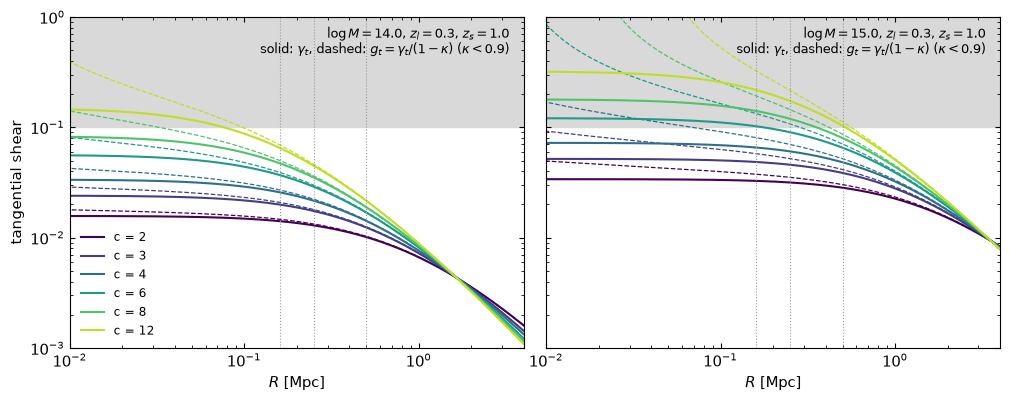

logM=14.0: g_t at 0.16 / 0.25 Mpc for c=4: 0.027, 0.022;  c=12: 0.069, 0.046
logM=15.0: g_t at 0.16 / 0.25 Mpc for c=4: 0.081, 0.070;  c=12: 0.324, 0.216


In [6]:
ZS = 1.0
Dl, Ds = Planck18.angular_diameter_distance(Z), Planck18.angular_diameter_distance(ZS)
Dls = Planck18.angular_diameter_distance(Z, ZS)
SIGCRIT = (const.c**2 / (4 * np.pi * const.G) * Ds / (Dl * Dls)).to(u.Msun / u.pc**2).value
fig, axs = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
for a, lm in zip(axs, (14.0, 15.0)):
    for c, col in zip(C_VALUES, cols):
        gam, kap = dsig(lm, c) / SIGCRIT, sigma(lm, c) / SIGCRIT
        a.plot(R, gam, color=col, label=f"c = {c:g}")
        g = np.where(kap < 0.9, gam / (1 - kap), np.nan)     # masked inside the (near-)Einstein radius
        a.plot(R, g, color=col, ls="--", lw=0.9)
    a.axhspan(0.1, 1, color="0.85", zorder=0)
    for r0 in INNER_CUTS:
        a.axvline(r0, color="0.6", lw=0.8, ls=":")
    a.set_xscale("log"); a.set_yscale("log"); a.set_xlim(1e-2, R_MAX); a.set_ylim(1e-3, 1)
    a.set_xlabel(r"$R$ [Mpc]"); a.tick_params(top=True, right=True, which="both")
    a.text(0.97, 0.97, rf"$\log M={lm}$, $z_l={Z}$, $z_s={ZS}$" + "\nsolid: $\\gamma_t$, dashed: $g_t=\\gamma_t/(1-\\kappa)$ ($\\kappa<0.9$)",
           transform=a.transAxes, ha="right", va="top", fontsize=9)
axs[0].set_ylabel("tangential shear"); axs[0].legend(frameon=False, fontsize=8.5, loc="lower left")
fig.subplots_adjust(wspace=0.05); plt.show()
for lm in (14.0, 15.0):
    print(f"logM={lm}: g_t at 0.16 / 0.25 Mpc for c=4: "
          + ", ".join(f"{np.interp(np.log(r), np.log(R), dsig(lm, 4.0) / SIGCRIT / (1 - sigma(lm, 4.0) / SIGCRIT)):.3f}" for r in (0.16, 0.25))
          + f";  c=12: " + ", ".join(f"{np.interp(np.log(r), np.log(R), dsig(lm, 12.0) / SIGCRIT / (1 - sigma(lm, 12.0) / SIGCRIT)):.3f}" for r in (0.16, 0.25)))

## 5. The rule: required depth over the $(M, c)$ plane

$r_{1/2}(M, c)$: the inner cut at which a halo keeps half of its full-depth concentration sensitivity.
Contours at the project's inner cuts. A cluster **above** a contour (higher $c$, lower $M$) needs data **inside**
that radius to keep half of its concentration information. (The grid takes ~1–2 min.)

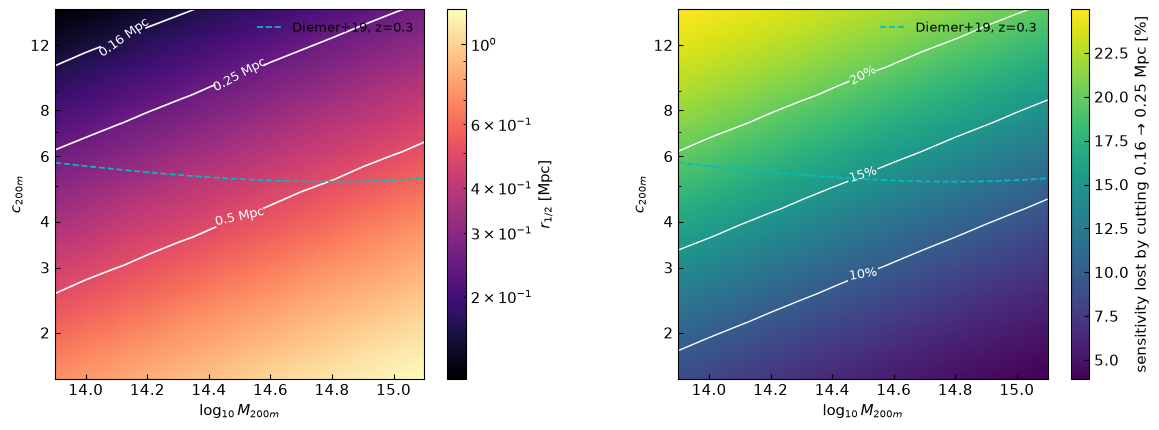

In [7]:
LM_GRID = np.linspace(13.9, 15.1, 13)
C_GRID = np.geomspace(1.5, 15, 14)
R_HALF = np.zeros((len(C_GRID), len(LM_GRID)))
LOSS = np.zeros_like(R_HALF)          # share of sensitivity in the 0.16-0.25 Mpc annulus
rgrid = np.logspace(-2.3, np.log10(2.0), 30)
for j, lm in enumerate(LM_GRID):
    for i, c in enumerate(C_GRID):
        s = np.array([sensitivity(lm, c, r) for r in rgrid])
        R_HALF[i, j] = np.exp(np.interp(-np.log(0.5 * s[0]), -np.log(s), np.log(rgrid)))
        LOSS[i, j] = 1 - np.exp(np.interp(np.log(0.25), np.log(rgrid), np.log(s))) / np.exp(np.interp(np.log(0.16), np.log(rgrid), np.log(s)))

fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))
fig.subplots_adjust(wspace=0.35)
im = axs[0].pcolormesh(LM_GRID, C_GRID, R_HALF, norm=colors.LogNorm(), cmap="magma", shading="gouraud")
cs = axs[0].contour(LM_GRID, C_GRID, R_HALF, levels=INNER_CUTS, colors="w", linewidths=1.2)
axs[0].clabel(cs, fmt=lambda v: f"{v:g} Mpc", fontsize=9)
fig.colorbar(im, ax=axs[0], label=r"$r_{1/2}$ [Mpc]")
im2 = axs[1].pcolormesh(LM_GRID, C_GRID, 100 * LOSS, cmap="viridis", shading="gouraud")
cs2 = axs[1].contour(LM_GRID, C_GRID, 100 * LOSS, levels=[10, 15, 20], colors="w", linewidths=1.0)
axs[1].clabel(cs2, fmt=lambda v: f"{v:.0f}%", fontsize=9)
fig.colorbar(im2, ax=axs[1], label="sensitivity lost by cutting 0.16 → 0.25 Mpc [%]")
lm_line = np.linspace(13.9, 15.1, 50)
for a in axs:
    a.plot(lm_line, [np.ravel(diemer19_c200m(10**v, Z))[0] for v in lm_line], "c--", lw=1.2, label=f"Diemer+19, z={Z}")
    a.set_yscale("log"); a.set_xlabel(r"$\log_{10} M_{200m}$"); a.set_ylabel(r"$c_{200m}$"); a.legend(frameon=False, fontsize=9, loc="upper right")
    a.set_yticks([2, 3, 4, 6, 8, 12]); a.set_yticklabels(["2", "3", "4", "6", "8", "12"]); a.yaxis.set_minor_formatter(plt.NullFormatter())
plt.show()

## 6. Which simulated clusters depend most on the inner bins?

Place the LSSTrb2 truth population ($\gamma_{cm,\rm true}=0.167$, N = 80,000) on the maps of §5, split by
magnitude-gap tercile. Since $\gamma_{cm} > 0$ and $\Delta m$ anticorrelates with mass, high-$\Delta m$ clusters sit at
high $c$ / low $M$ — exactly where the innermost bins carry most of the concentration information.
(Maps are at $z=0.3$; the population spans $z$ = 0.1–0.6, so this is indicative.)

N = 80000 truth clusters; c range 5-95%: [2.68 5.65]
   Delta m tercile  median c  median logM  median r_1/2  r_1/2<0.25  r_1/2<0.16  loss 0.16->0.25
            low Δm      3.33        14.38         0.551        0.0%        0.0%            11.7%
            mid Δm      4.23        14.35         0.447        0.0%        0.0%            14.1%
           high Δm      5.07        14.28         0.374        0.1%        0.0%            16.0%


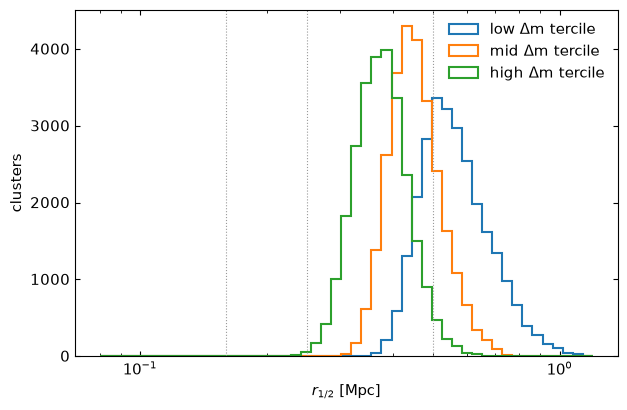

In [8]:
from scipy.interpolate import RegularGridInterpolator
t = np.load(TRUTH_PATH)
lm_t, c_t, dm_t = np.log10(t["M_halo"]), t["concentration"], t["delta_m"]
pts = np.column_stack([np.clip(np.log(c_t), np.log(C_GRID[0]), np.log(C_GRID[-1])), np.clip(lm_t, LM_GRID[0], LM_GRID[-1])])
rh_t = np.exp(RegularGridInterpolator((np.log(C_GRID), LM_GRID), np.log(R_HALF))(pts))
loss_t = RegularGridInterpolator((np.log(C_GRID), LM_GRID), LOSS)(pts)
edges = np.quantile(dm_t, [0, 1/3, 2/3, 1])
print(f"N = {len(lm_t)} truth clusters; c range 5-95%: {np.percentile(c_t, [5, 95]).round(2)}")
print(f"{'Delta m tercile':>18s} {'median c':>9s} {'median logM':>12s} {'median r_1/2':>13s} {'r_1/2<0.25':>11s} {'r_1/2<0.16':>11s} {'loss 0.16->0.25':>16s}")
fig, ax = plt.subplots(figsize=(7, 4.5))
for k, lab in enumerate(["low", "mid", "high"]):
    m = (dm_t >= edges[k]) & (dm_t <= edges[k + 1])
    print(f"{lab + ' Δm':>18s} {np.median(c_t[m]):9.2f} {np.median(lm_t[m]):12.2f} {np.median(rh_t[m]):13.3f} "
          f"{np.mean(rh_t[m] < 0.25):11.1%} {np.mean(rh_t[m] < 0.16):11.1%} {np.median(loss_t[m]):16.1%}")
    ax.hist(rh_t[m], bins=np.geomspace(0.08, 1.2, 50), histtype="step", lw=1.5, label=f"{lab} Δm tercile")
for r0 in INNER_CUTS:
    ax.axvline(r0, color="0.6", lw=0.8, ls=":")
ax.set_xscale("log"); ax.set_xlabel(r"$r_{1/2}$ [Mpc]"); ax.set_ylabel("clusters"); ax.legend(frameon=False)
ax.tick_params(top=True, right=True, which="both"); plt.show()

## 7. Is the simulator consistent with the model in the inner bins, at high $c$?

Checked 2026-09-28 with the simulator's own per-cluster pipeline (`simulate_lensing` → `bootstrap_signal`), 300
identical spherical centred haloes, **no shape noise**, LSST bins (0.16–3.98 Mpc), mean data / bin-averaged model:

| log M | c | z | 0.16 | 0.25 | 0.40 | 0.63 | 1.0 | 1.6 | 2.5 | 4.0 |
|---|---|---|---|---|---|---|---|---|---|---|
| 14.5 | 3 | 0.3 | 1.000 | 1.002 | 1.000 | 1.000 | 1.001 | 1.000 | 1.000 | 1.002 |
| 14.5 | 10 | 0.3 | 1.000 | 1.003 | 0.999 | 0.999 | 1.001 | 1.000 | 1.000 | 1.002 |
| 15.0 | 12 | 0.3 | 0.999 | 1.003 | 1.000 | 0.999 | 1.001 | 1.000 | 1.000 | 1.002 |
| 14.0 | 12 | 0.3 | 0.998 | 1.003 | 0.999 | 0.999 | 1.001 | 1.000 | 1.000 | 1.002 |
| 15.0 | 12 | 0.15 | 0.999 | 1.001 | 1.001 | 0.999 | 1.000 | 1.000 | 1.000 | 1.002 |

No concentration-dependent mismatch. If the innermost bin drives the LSST $\gamma_{cm}$ offset, the mechanism must
involve noise (sparse, heterogeneously occupied inner bins; per-cluster bootstrap covariances), which is what the
LSSTcleanR25 control (fit from 0.25 Mpc) tests.